# 04 · Проверка цели, ошибок, охвата и переносимости

## tl;dr

Проверены условные интервалы, отдельный столбец отказов, трудные записи, synthetic probes, связь с исходом и изменение PPV при гипотетической распространённости. Все данные уже изучались; новая ревизия не создаёт независимого клинического test.

| Профиль | Macro-F1 на принятых | Recall abnormal | Охват JNU |
|---|---:|---:|---:|
| core3 | 0.673 | 63.8% | 99.87% |
| report4s5 | 0.720 | 70.8% | 99.79% |
| report5 | 0.722 | 70.7% | 99.79% |
| report7 | 0.732 | 72.1% | 99.79% |

Охват JNU относится к полноте собственных измерений; он не означает такой же охват больничных отчётов с неизвестными определениями.


## Context & Methods
### Key Assumptions
1000 patient-component bootstrap-выборок условны на выполненных CV fits и принятых входах. Неопределённость всего переобучения и переноса не охвачена. Synthetic probes проверяют поведение и API, но не создают клинически размеченные случаи. Охват JNU и возможность принять реальный бланк — разные величины.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · интервалы и отдельный учёт отказов

In [5]:
from src.training.ctg_review_assessment import jnu_assessment
if not (JNU/'conditional_intervals.csv').exists():jnu_assessment()
intervals=pd.read_csv(JNU/'conditional_intervals.csv');coverage=pd.read_csv(JNU/'coverage_summary.csv')
display(intervals[(intervals.family=='selected_procedure')&intervals.metric.isin(['macro_f1','recall','specificity','ap'])].round(4))
display(coverage.round(5))


,profile,family,metric,estimate,ci_low,ci_high,bootstrap,conditional_on
16,core3,selected_procedure,macro_f1,0.6731,0.6662,0.6806,1000,accepted inputs and fixed exploratory CV fits
17,core3,selected_procedure,recall,0.6381,0.6284,0.6486,1000,accepted inputs and fixed exploratory CV fits
18,core3,selected_procedure,specificity,0.7149,0.7047,0.7250,1000,accepted inputs and fixed exploratory CV fits
20,core3,selected_procedure,ap,0.7861,0.7777,0.7942,1000,accepted inputs and fixed exploratory CV fits
48,report4s5,selected_procedure,macro_f1,0.7204,0.7131,0.7271,1000,accepted inputs and fixed exploratory CV fits
49,report4s5,selected_procedure,recall,0.7081,0.6983,0.7182,1000,accepted inputs and fixed exploratory CV fits
50,report4s5,selected_procedure,specificity,0.7363,0.7260,0.7466,1000,accepted inputs and fixed exploratory CV fits
52,report4s5,selected_procedure,ap,0.8354,0.8280,0.8430,1000,accepted inputs and fixed exploratory CV fits
80,report5,selected_procedure,macro_f1,0.7223,0.7151,0.7289,1000,accepted inputs and fixed exploratory CV fits
81,report5,selected_procedure,recall,0.7072,0.6974,0.7175,1000,accepted inputs and fixed exploratory CV fits


,profile,actual,records,accepted,abstained,coverage
0,core3,0,9598,9593,5,0.99948
1,core3,1,11171,11150,21,0.99812
2,report4s5,0,9598,9591,7,0.99927
3,report4s5,1,11171,11135,36,0.99678
4,report5,0,9598,9591,7,0.99927
5,report5,1,11171,11135,36,0.99678
6,report7,0,9598,9591,7,0.99927
7,report7,1,11171,11135,36,0.99678


## Results · качество, интервалы и поддержка

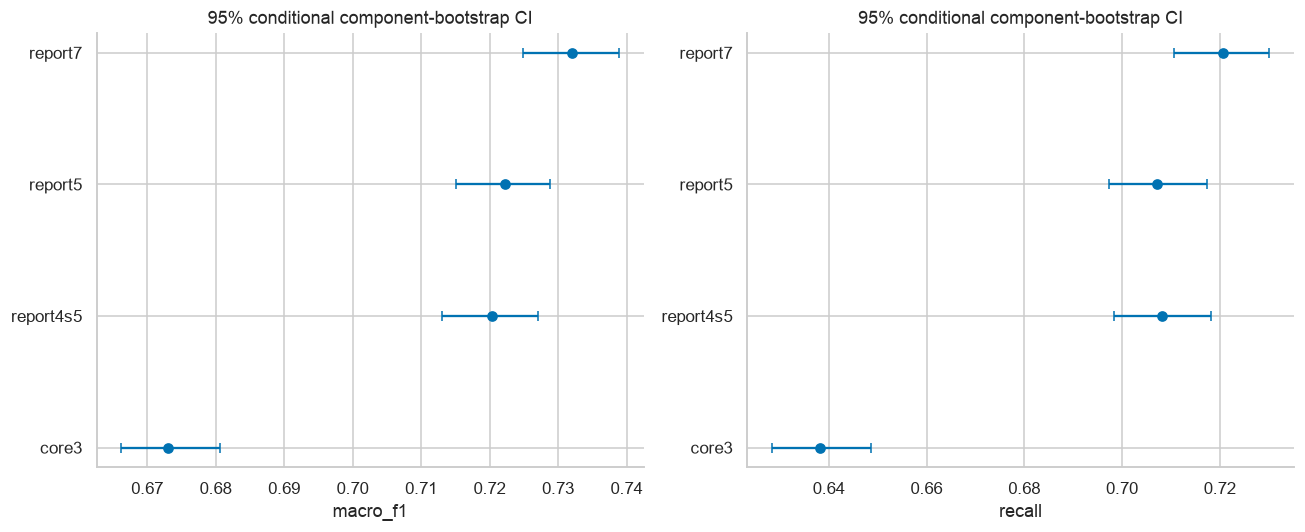

,representation,metric,estimate,ci_low,ci_high
0,fhr_std_only,macro_f1,0.7439,0.7376,0.7506
1,fhr_std_only,ap,0.8593,0.8530,0.8654
2,fhr_std_only,roc_auc,0.8172,0.8106,0.8233
3,published_F_quarantined,macro_f1,0.8952,0.8906,0.9001
4,published_F_quarantined,ap,0.9710,0.9689,0.9731
5,published_F_quarantined,roc_auc,0.9644,0.9620,0.9668
6,quality_only,macro_f1,0.6222,0.6148,0.6294
7,quality_only,ap,0.6547,0.6436,0.6657
8,quality_only,roc_auc,0.6495,0.6410,0.6576
9,raw_minute210,macro_f1,0.7771,0.7704,0.7837


,comparison,metric,mean,ci_low,ci_high
0,fhr_std_only minus report5,macro_f1,0.0226,0.0148,0.0301
1,fhr_std_only minus report5,ap,0.0225,0.0165,0.0288
2,fhr_std_only minus report5,roc_auc,0.0189,0.0120,0.0263
3,published_F_quarantined minus report5,macro_f1,0.1737,0.1664,0.1809
4,published_F_quarantined minus report5,ap,0.1343,0.1279,0.1410
5,published_F_quarantined minus report5,roc_auc,0.1661,0.1598,0.1724
6,quality_only minus report5,macro_f1,-0.0994,-0.1090,-0.0903
7,quality_only minus report5,ap,-0.1822,-0.1929,-0.1712
8,quality_only minus report5,roc_auc,-0.1491,-0.1591,-0.1390
9,raw_minute210 minus report5,macro_f1,0.0556,0.0479,0.0632


In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,metric in zip(axes,['macro_f1','recall']):
    z=intervals[(intervals.family=='selected_procedure')&(intervals.metric==metric)].reset_index(drop=True)
    ax.errorbar(z.estimate,np.arange(len(z)),xerr=np.array([z.estimate-z.ci_low,z.ci_high-z.estimate]),fmt='o',capsize=3,color='#0072b2')
    ax.set(yticks=range(len(z)),yticklabels=z.profile,xlabel=metric,title='95% conditional component-bootstrap CI')
fig.tight_layout();save_show('jnu04_intervals.png')
display(pd.read_csv(JNU/'representation_intervals.csv').round(4))
display(pd.read_csv(JNU/'representation_paired_differences.csv').round(4))


### PR и калибровка на внешних OOF

Для редких probability bins показана поддержка независимых компонент. Бины с <30 компонентами остаются отдельными открытыми маркерами и не соединяются линией: их доля ошибок нестабильна. Это диагностический срез, модель по нему не меняется.


,family,bin,records,patient_components,mean_probability,observed_fraction
0,catboost,0,1,1,0.0979,0.0000
10,linear,0,5,5,0.0773,0.7143
20,selected_procedure,0,8,8,0.0957,0.1132
30,spline,0,7,7,0.0956,0.1224


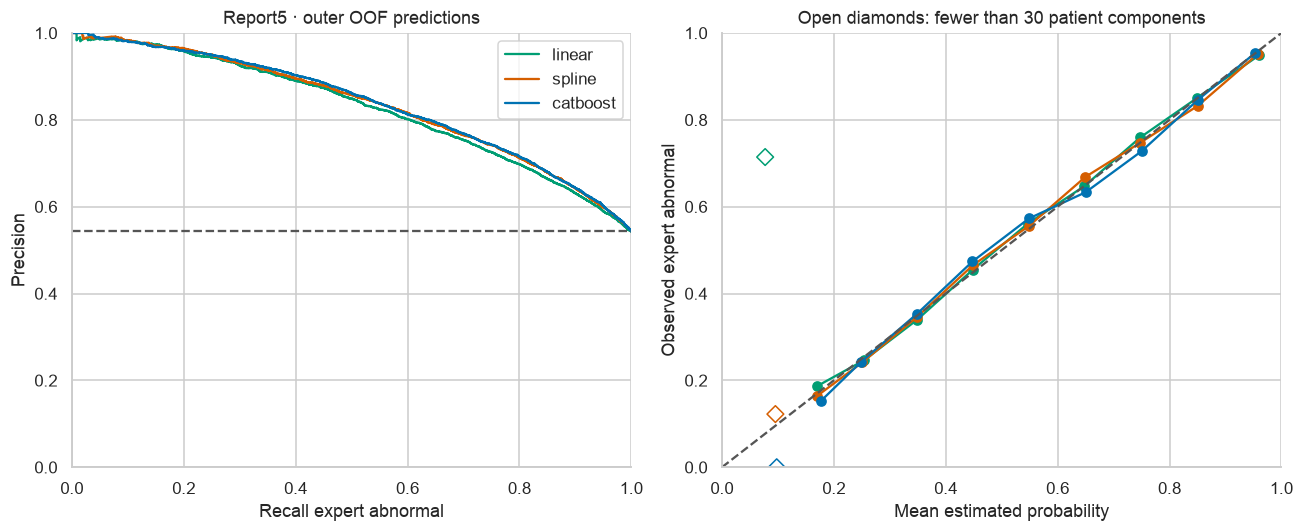

In [9]:
from sklearn.metrics import precision_recall_curve
from src.training.ctg_review_models import weights
from src.training.ctg_review_assessment import jnu_calibration_support
if not (JNU/'calibration_bin_support.csv').exists():jnu_calibration_support()
bins=pd.read_csv(JNU/'calibration_bin_support.csv')
display(bins[bins.patient_components<30].round(4))
predictions=pd.read_parquet(JNU/'nested_predictions.parquet')
fig,axes=plt.subplots(1,2,figsize=(12,5))
for family in ['linear','spline','catboost']:
    z=predictions[(predictions.profile=='report5')&(predictions.family==family)&predictions.accepted].copy()
    z['_weight']=weights(z.patient_id);precision,recall,_=precision_recall_curve(z.figo_label,z.p,sample_weight=z['_weight'])
    axes[0].plot(recall,precision,color=COLORS[family],label=family)
    a=bins[(bins.family==family)&(bins.patient_components>=30)]
    axes[1].plot(a.mean_probability,a.observed_fraction,'o-',color=COLORS[family],label=family)
    rare=bins[(bins.family==family)&(bins.patient_components<30)]
    axes[1].scatter(rare.mean_probability,rare.observed_fraction,marker='D',facecolors='none',edgecolors=COLORS[family],s=60)
axes[0].axhline(np.average(z.figo_label,weights=z['_weight']),ls='--',color='#555555')
axes[0].set(xlabel='Recall expert abnormal',ylabel='Precision',xlim=(0,1),ylim=(0,1),title='Report5 · outer OOF predictions')
axes[1].plot([0,1],[0,1],'--',color='#555555');axes[1].set(xlabel='Mean estimated probability',ylabel='Observed expert abnormal',xlim=(0,1),ylim=(0,1),title='Open diamonds: fewer than 30 patient components')
axes[0].legend();fig.tight_layout();save_show('jnu04_pr_calibration.png')


### Матрица с отказом и качество трудных записей

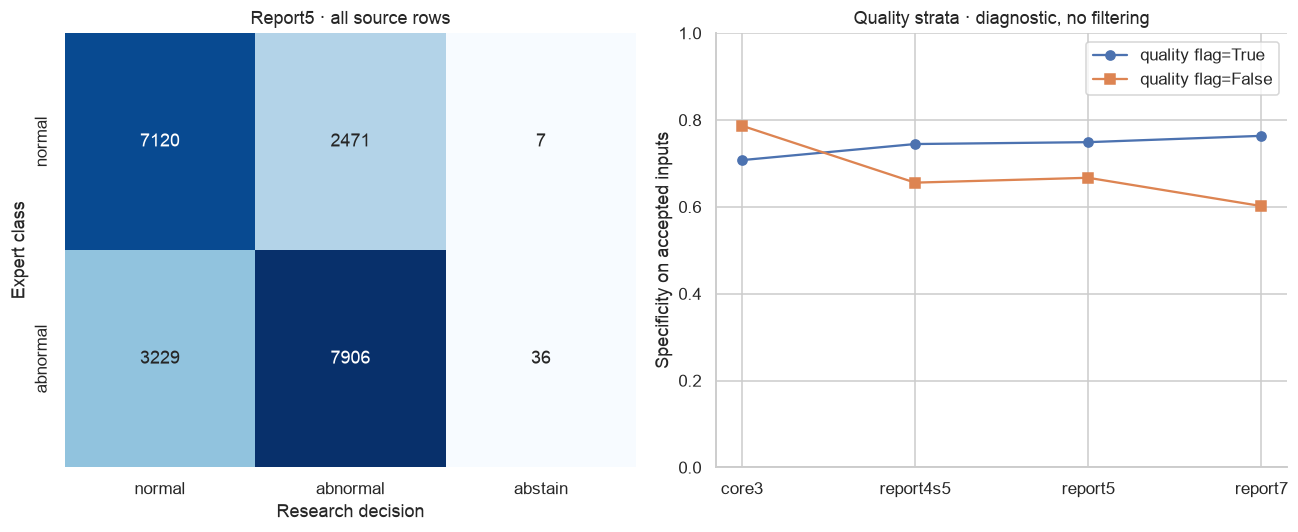

,profile,quality_flag,source_records,accepted_records,group_macro_f1,group_recall,group_specificity
0,core3,False,3508,3482,0.5635,0.4952,0.7868
1,core3,True,17261,17261,0.6941,0.6809,0.7075
2,report4s5,False,3508,3465,0.6427,0.6907,0.6557
3,report4s5,True,17261,17261,0.7299,0.7153,0.7446
4,report5,False,3508,3465,0.6463,0.6898,0.6669
5,report5,True,17261,17261,0.7315,0.7143,0.7489
6,report7,False,3508,3465,0.6620,0.7543,0.6017
7,report7,True,17261,17261,0.7368,0.7105,0.7634


,grouping,stratum,source_records,accepted_records,abnormal_records,metrics_supported,group_macro_f1,group_recall,group_specificity,group_precision,group_log_loss,group_ap,group_auc,group_brier,records,groups
0,stv_stratum,"[-inf, 4.0)",486,486,252,True,0.7096,0.7196,0.6996,0.7226,0.5698,0.8062,0.7734,0.1955,486.0,469.0
1,stv_stratum,"[15.0, inf)",1034,1034,922,True,0.5974,0.9766,0.1740,0.9056,0.2674,0.9771,0.8441,0.0810,1034.0,952.0
2,stv_stratum,"[4.0, 15.0)",19206,19206,9961,True,0.7145,0.6848,0.7475,0.7503,0.5517,0.8154,0.7879,0.1870,19206.0,12015.0
3,stv_stratum,NaN,43,0,36,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,uc_signature,max100,12891,12868,7036,True,0.7239,0.7153,0.7374,0.7719,0.5363,0.8418,0.7991,0.1813,12868.0,9436.0
5,uc_signature,max127,1214,1213,553,True,0.6862,0.6621,0.7106,0.6586,0.5968,0.7384,0.7552,0.2038,1213.0,1121.0
6,uc_signature,other,6664,6645,3582,True,0.7285,0.7000,0.7617,0.7721,0.5286,0.8419,0.8070,0.1782,6645.0,5017.0


,record_id,figo_label,p,baseline_bpm,stv_ms,amplitude_bpm,acc15_per_10min,dec15_per_10min
6877,28591_1_210208000001,1.0,0.0943,133.8913,7.0549,16.4333,2.6667,0.0
10957,10628_1_210208000001,1.0,0.1144,141.1570,8.4458,19.9667,3.3333,0.0
2355,38945_1_210208000001,1.0,0.1153,131.6133,6.1877,15.1000,2.3333,0.0
11497,24484_1_210208000001,1.0,0.1167,125.7536,8.5008,19.5000,3.3333,0.0
15995,20922_1_210208000001,1.0,0.1176,130.0934,7.7825,17.3793,2.3333,0.0
16362,31055_1_210208000001,1.0,0.1194,132.0903,10.6854,14.8333,0.0000,0.0
15632,11307_1_210208000001,1.0,0.1223,143.6335,5.9771,12.0000,1.0000,0.0
16268,28786_1_210208000001,1.0,0.1233,130.3623,8.1208,17.3200,2.0000,0.0
2440,4257_1_210208000001,1.0,0.1235,137.7932,6.9323,19.3667,3.6667,0.0
6477,18599_1_210208000001,1.0,0.1273,129.8712,6.0423,13.0000,1.3333,0.0


In [11]:
conf=pd.read_csv(JNU/'confusions_with_abstention.csv')
q=pd.read_csv(JNU/'quality_subgroups.csv')
fig,axes=plt.subplots(1,2,figsize=(12,5))
z=conf[(conf.profile=='report5')&(conf.family=='selected_procedure')].pivot(index='actual',columns='predicted',values='records').reindex(index=[0,1],columns=[0,1,2])
sns.heatmap(z,annot=True,fmt='d',cmap='Blues',cbar=False,ax=axes[0],xticklabels=['normal','abnormal','abstain'],yticklabels=['normal','abnormal'])
axes[0].set(title='Report5 · all source rows',xlabel='Research decision',ylabel='Expert class')
for flag,marker in [(True,'o'),(False,'s')]:
    z=q[q.quality_flag==flag];axes[1].plot(z.profile,z.group_specificity,marker+'-',label=f'quality flag={flag}')
axes[1].set(ylabel='Specificity on accepted inputs',ylim=(0,1),title='Quality strata · diagnostic, no filtering');axes[1].legend()
fig.tight_layout();save_show('jnu04_abstention_and_quality.png')
display(q[['profile','quality_flag','source_records','accepted_records','group_macro_f1','group_recall','group_specificity']].round(4))
display(pd.read_csv(JNU/'input_subgroup_metrics.csv').round(4))
errors=pd.read_csv(JNU/'selected_procedure_error_cases.csv')
display(errors[(errors.profile=='report5')&(errors.error_type=='false_negative')].sort_values('wrong_class_confidence',ascending=False).head(10)[['record_id','figo_label','p','baseline_bpm','stv_ms','amplitude_bpm','acc15_per_10min','dec15_per_10min']].round(4))


### Synthetic probes и единый клинический отказ

In [13]:
probes=pd.read_json(JNU/'synthetic_pattern_probes.json')
display(probes[probes.profile=='report5'][['family','pattern','status','probability_expert_abnormal','clinical_risk']])
display(pd.read_csv(JNU/'synthetic_joint_support.csv'))
from src.features.ctg_report_contract import research_patterns,evaluate_report,partial_dr_checklist
export=ROOT/'models/exported/jnu_ctg/reviewed_v2'
bundle=joblib.load(export/'report5_catboost.joblib')
for name,report in research_patterns().items():
    result=bundle.assess_report(report)
    assert result['clinical_risk'] is None and result['probability_expert_abnormal'] is None
display(pd.DataFrame(partial_dr_checklist(research_patterns()['quiet'])['requirements']))
print('Порядок вероятностей этих искусственных сочетаний — свойство expert-label модели, не валидированная шкала благополучия.')


Порядок вероятностей этих искусственных сочетаний — свойство expert-label модели, не валидированная шкала благополучия.


,family,pattern,status,probability_expert_abnormal,clinical_risk
12,linear,quiet,research_prediction,0.097895,NaN
13,linear,reactive,research_prediction,0.354881,NaN
14,linear,high_variation,research_prediction,0.836832,NaN
15,linear,decelerative,research_prediction,0.949283,NaN
16,spline,quiet,research_prediction,0.220530,NaN
17,spline,reactive,research_prediction,0.336107,NaN
18,spline,high_variation,research_prediction,0.869658,NaN
19,spline,decelerative,research_prediction,0.915353,NaN
20,catboost,quiet,research_prediction,0.263342,NaN
21,catboost,reactive,research_prediction,0.281557,NaN


,pattern,original_train_records_in_box,patients,FIGO_abnormal_fraction_if_n_ge20,box
0,quiet,18,18,NaN,"baseline ±10 BPM, STV ±1 ms, range ±3 BPM; AC/DC rates exact; descriptive not clinical validation"
1,reactive,34,34,0.323529,"baseline ±10 BPM, STV ±1 ms, range ±3 BPM; AC/DC rates exact; descriptive not clinical validation"
2,high_variation,0,0,NaN,"baseline ±10 BPM, STV ±1 ms, range ±3 BPM; AC/DC rates exact; descriptive not clinical validation"
3,decelerative,0,0,NaN,"baseline ±10 BPM, STV ±1 ms, range ±3 BPM; AC/DC rates exact; descriptive not clinical validation"


,requirement,status
0,STV >3 ms in the specified implementation,not_evaluable
1,Gestation-dependent high-variation LTV centiles,not_evaluable
2,Verified high-variation episode and sinusoidal assessment,not_evaluable
3,Movement/acceleration combination with verified event definitions,not_evaluable
4,Deceleration area categories including >100 lost beats,not_evaluable
5,Terminal epoch deceleration and artifact checks,not_evaluable


### Цель, исход и гипотетическая распространённость

Patient-level any_abnormal использует все опубликованные записи пациентки; без хронологии это описательная связь, а не прогноз на дату одной КТГ. Изменение метки между разными записями не измеряет согласие экспертов на одном сигнале. Сценарий 15% ниже не является измеренной клинической распространённостью.


,different trace pairs
unordered_pairs,12767
symmetrized_pair_kappa,0.056056
interpretation,"Different recordings, not repeated annotations of the same trace; not inter-rater reliability."


,figo_label,count,sum,mean
0,0.0,9568,72.0,0.00753
1,1.0,11143,82.0,0.00736


,any_abnormal,count,sum,mean
0,0.0,4249,26.0,0.00612
1,1.0,8319,65.0,0.00781


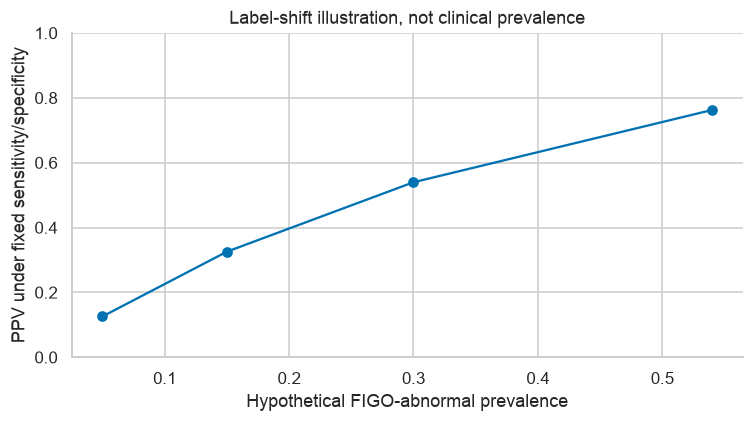

In [15]:
display(pd.Series(json.loads((REVIEW/'jnu_label_agreement.json').read_text())).to_frame('different trace pairs'))
display(pd.read_csv(REVIEW/'jnu_outcome_record_association.csv').round(5))
display(pd.read_csv(REVIEW/'jnu_outcome_patient_association.csv').round(5))
shift=pd.read_csv(JNU/'hypothetical_label_shift_ppv.csv');z=shift[(shift.profile=='report5')&(shift.family=='selected_procedure')]
fig,ax=plt.subplots(figsize=(7,4));ax.plot(z.assumed_FIGO_prevalence,z.ppv_under_constant_sensitivity_specificity,'o-',color='#0072b2')
ax.set(xlabel='Hypothetical FIGO-abnormal prevalence',ylabel='PPV under fixed sensitivity/specificity',ylim=(0,1),title='Label-shift illustration, not clinical prevalence')
fig.tight_layout();save_show('jnu04_hypothetical_ppv.png')


## Takeaways

Цель — морфологическая метка normal/abnormal JNU. Она не заменяет клинический исход или полные критерии Доуза–Редмана. Совместимость с российским прибором не подтверждена; общий вход приложения возвращает отказ до модели. Сырые сигналы нужны только для исследования измерений, не обязательны для будущего приложения.
